In [1]:
!pip -q install librosa soundfile matplotlib numpy

In [2]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

In [8]:
 #######WYRAZ#####
 from google.colab import files
 uploaded = files.upload()   # wybierz plik .wav z dysku

def wczytaj_audio(sciezka=None):
    """Wczytuje audio do 16 kHz mono. Bez pliku zwraca sygnał syntetyczny."""
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

# Podmień None na nazwę własnego pliku, np. 'moje_nagranie.wav'
y, sr = wczytaj_audio("informatyka.mp3")

print(f"Liczba próbek: {len(y)}")
print(f"Częstotliwość próbkowania: {sr} Hz")
print(f"Czas trwania: {len(y) / sr:.2f} s")

Saving informatyka.mp3 to informatyka (1).mp3
Liczba próbek: 14800
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 0.93 s


In [9]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

S_db = log_mel(y, sr)
M = mfcc(y, sr)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (64, 93)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 93)  (współczynniki × ramki czasowe)


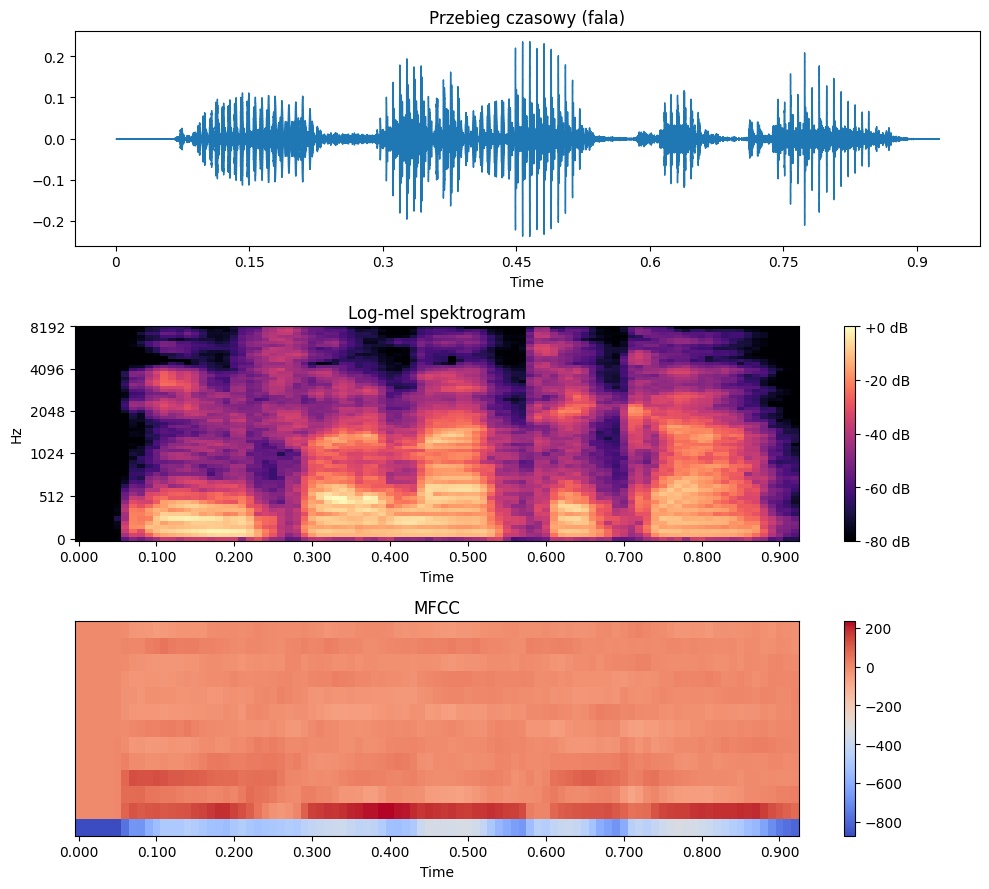

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala)")

img1 = librosa.display.specshow(
    S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

In [14]:
 from google.colab import files
 uploaded = files.upload()   # wybierz plik .wav z dysku

def wczytaj_audio(sciezka):
    """Wczytuje audio do 16 kHz mono. Bez pliku zwraca sygnał syntetyczny."""
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

# Podmień None na nazwę własnego pliku, np. 'moje_nagranie.wav'
y, sr = wczytaj_audio("pollub.mp3")

print(f"Liczba próbek: {len(y)}")
print(f"Częstotliwość próbkowania: {sr} Hz")
print(f"Czas trwania: {len(y) / sr:.2f} s")

Saving pollub.mp3 to pollub (1).mp3
Liczba próbek: 37840
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.37 s


In [15]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

S_db = log_mel(y, sr)
M = mfcc(y, sr)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (64, 237)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 237)  (współczynniki × ramki czasowe)


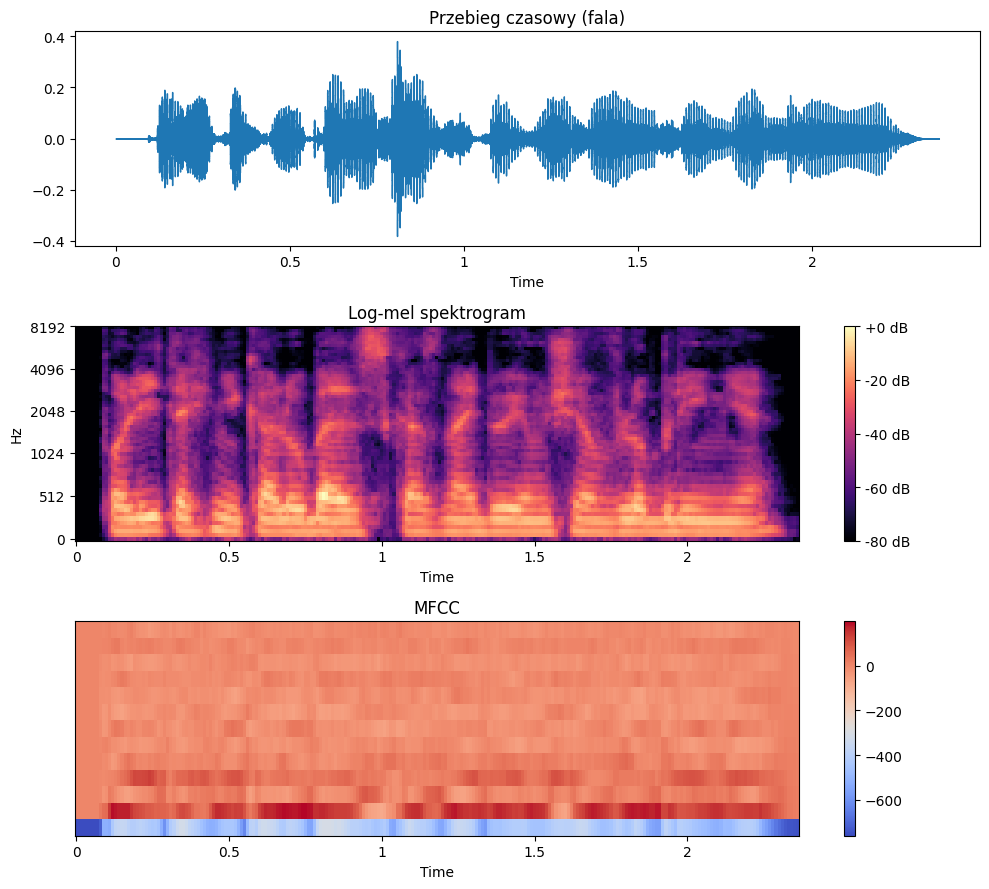

In [16]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala)")

img1 = librosa.display.specshow(
    S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

WNIOSKI: Podczas ćwiczenia porównałem reprezentacje log-Mel Spectrogram i MFCC dla nagrań mowy. Zmieniając wartości n_fft i hop_length, można było zauważyć, że wpływają one na wygląd spektrogramu i ilość widocznych szczegółów.